# Group-welfare tail drift

This notebook measures whether the distribution of mean group welfare has stabilized by the end of each simulation. It deliberately treats both convergence to a constant and persistent stationary fluctuations as stable.

The final time interval is split into equal consecutive blocks. For each adjacent pair, the one-dimensional Wasserstein distance is computed, and the largest distance is reported directly:

$$D = \max_i W_1(B_i, B_{i+1}).$$

A drift of zero means the tail distributions are identical. Larger values mean that the welfare regime is still changing.

In [1]:
import gc
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401 - registers the science style
import xarray as xr
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline
plt.style.use("science")
# Raw scatter points make SVG notebook output unnecessarily large.
set_matplotlib_formats("png")
extra = 3
plt.rcParams.update({
    "font.size": 14 + extra,
    "axes.titlesize": 17 + extra,
    "axes.labelsize": 15 + extra,
    "xtick.labelsize": 12 + extra,
    "ytick.labelsize": 12 + extra,
    "figure.titlesize": 19 + extra,
})

project_root = next(
    (
        path
        for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
        if (path / "pyproject.toml").is_file() and (path / "tasks").is_dir()
    ),
    None,
)
if project_root is None:
    raise RuntimeError("Run this notebook from the network-creation repository.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from network_creation.plotting.plot_pair import plot_2d_descriptor
from tasks.policies import load_policy_results

In [2]:
CONFIG = {
    "result_store": (
        project_root
        / "artifacts"
        / "simulation_runs"
        / "run-20260809T034029.zarr"
    ),
    "observable": "centered_mean_welfare.mean",
    "tail_duration": 10.0,
    "n_blocks": 2,
    "parameter_chunk_size": 1024,
    "plot": {
        "cmap": "jet",
        "point_size": 4.0,
        "point_alpha": 1.0,
        "pair_atol": 1e-5,
        "panel_side": 2.35,
        "row_label_width": 0.5,
        "strip_height": 0.38,
        "spacing": 0.04,
        "font_sizes": {
            "axis_ticks": 18,
            "axis_labels": 21,
            "column_headers": 20,
            "row_headers": 20,
            "colorbar_ticks": 18,
            "colorbar_label": 21,
        },
    },
    "export": {
        "output_root": project_root / "artifacts" / "figures",
        "dpi": 300,
    },
}

if CONFIG["tail_duration"] <= 0.0:
    raise ValueError("tail_duration must be positive")
if CONFIG["n_blocks"] < 2:
    raise ValueError("n_blocks must be at least two")

In [3]:
results = load_policy_results(
    CONFIG["result_store"],
    stats=CONFIG["observable"],
    normalize_time=True,
)
if results.attrs["has_failures"]:
    raise RuntimeError("The source run contains failed rows.")

welfare = results["x"].sel(
    observable=CONFIG["observable"],
    drop=True,
)
composition_dims = tuple(
    dim
    for dim in welfare.dims
    if dim not in {"n_agents", "parameter_row", "step"}
)
if len(composition_dims) != 1:
    raise ValueError(
        f"Expected one policy-composition dimension, found {composition_dims}."
    )
composition_dim = composition_dims[0]
if results.sizes[composition_dim] != 1:
    raise ValueError(
        "This homogeneous-agent analysis expects exactly one composition value."
    )
composition = results.coords[composition_dim].values[0].item()

loaded_path = Path(results.attrs["result_store_path"])
print(f"Loaded {loaded_path.relative_to(project_root)}")
print(f"Rows per network size: {results.sizes['parameter_row']:,}")
print(f"Network sizes: {results.coords['n_agents'].values.tolist()}")
print(f"Time range: {float(welfare.step[0]):g} to {float(welfare.step[-1]):g}")
print(f"Time axis: {results.attrs['time_axis']}")

Loaded artifacts/simulation_runs/run-20260809T034029.zarr
Rows per network size: 32,768
Network sizes: [10, 50, 100]
Time range: 0 to 60
Time axis: activation_opportunities_per_agent


In [4]:
def adjacent_wasserstein_drift(values, n_blocks):
    """Return the maximum W1 distance between equal-sized adjacent blocks."""
    values = np.asarray(values, dtype=np.float32)
    if values.shape[-1] % n_blocks:
        raise ValueError("The time axis must divide evenly into blocks.")

    valid = np.isfinite(values).all(axis=-1)
    safe_values = np.where(np.isfinite(values), values, 0.0)
    block_size = values.shape[-1] // n_blocks
    blocks = safe_values.reshape(*values.shape[:-1], n_blocks, block_size)
    ordered = np.sort(blocks, axis=-1)
    adjacent_distances = np.mean(
        np.abs(ordered[..., 1:, :] - ordered[..., :-1, :]),
        axis=-1,
    )
    drift = np.max(adjacent_distances, axis=-1).astype(np.float32, copy=False)
    return np.where(valid, drift, np.nan).astype(np.float32, copy=False)


step_values = np.asarray(welfare.step.values, dtype=np.float64)
if step_values.size < 2:
    raise ValueError("The welfare output must contain a time series.")
step_deltas = np.diff(step_values)
time_step = float(np.median(step_deltas))
if time_step <= 0.0 or not np.allclose(step_deltas, time_step):
    raise ValueError("Expected a regular normalized time grid.")

block_duration = CONFIG["tail_duration"] / CONFIG["n_blocks"]
samples_per_block = int(round(block_duration / time_step))
if samples_per_block < 2 or not np.isclose(
    samples_per_block * time_step,
    block_duration,
):
    raise ValueError("Each requested block must align with the normalized time grid.")
tail_sample_count = CONFIG["n_blocks"] * samples_per_block
if tail_sample_count >= welfare.sizes["step"]:
    raise ValueError("The requested tail is not shorter than the recorded horizon.")
tail = welfare.isel(step=slice(-tail_sample_count, None))

drift_by_n = []
chunk_size = CONFIG["parameter_chunk_size"]
for n_agents in welfare.coords["n_agents"].values:
    selected = tail.sel(n_agents=int(n_agents), drop=True)
    chunk_drifts = []
    for start in range(0, selected.sizes["parameter_row"], chunk_size):
        chunk = selected.isel(
            parameter_row=slice(start, min(start + chunk_size, selected.sizes["parameter_row"]))
        )
        values = adjacent_wasserstein_drift(
            chunk.to_numpy(),
            CONFIG["n_blocks"],
        )
        output_dims = chunk.dims[:-1]
        chunk_drifts.append(
            xr.DataArray(
                values,
                dims=output_dims,
                coords={dim: chunk.coords[dim] for dim in output_dims},
            )
        )
    size_drift = xr.concat(chunk_drifts, dim="parameter_row").sortby(
        "parameter_row"
    )
    drift_by_n.append(size_drift.expand_dims(n_agents=[int(n_agents)]))
    print(f"Computed n={int(n_agents)}")

tail_distribution_drift = xr.concat(drift_by_n, dim="n_agents").rename(
    "tail_distribution_drift"
)
tail_distribution_drift.attrs.update({
    "long_name": "maximum adjacent-window Wasserstein distance",
    "tail_duration": CONFIG["tail_duration"],
    "n_blocks": CONFIG["n_blocks"],
    "block_duration": block_duration,
})
metrics = xr.Dataset({
    "tail_distribution_drift": tail_distribution_drift,
})

del tail, welfare
results = results.drop_vars("x")
_ = gc.collect()

Computed n=10
Computed n=50
Computed n=100


In [5]:
print(
    f"Tail: final {CONFIG['tail_duration']:g} activation opportunities per agent; "
    f"{CONFIG['n_blocks']} blocks of {block_duration:g}"
)
for n_agents in metrics.coords["n_agents"].values:
    values = metrics["tail_distribution_drift"].sel(n_agents=n_agents).to_numpy()
    quantiles = np.nanquantile(values, [0.05, 0.5, 0.95, 1.0])
    print(
        f"n={int(n_agents):>3}: "
        f"D p05={quantiles[0]:.4f}, median={quantiles[1]:.4f}, "
        f"p95={quantiles[2]:.4f}, max={quantiles[3]:.4f}"
    )
display(metrics)

Tail: final 10 activation opportunities per agent; 2 blocks of 5
n= 10: D p05=0.0000, median=0.0059, p95=0.0323, max=0.1069
n= 50: D p05=0.0000, median=0.0020, p95=0.0208, max=0.1109
n=100: D p05=0.0000, median=0.0012, p95=0.0139, max=0.1050


<xarray.Dataset> Size: 655kB
Dimensions:                   (n_agents: 3, best_response_proportion: 1,
                               parameter_row: 32768)
Coordinates:
  * n_agents                  (n_agents) int64 24B 10 50 100
  * best_response_proportion  (best_response_proportion) float32 4B 1.0
  * parameter_row             (parameter_row) int64 262kB 0 1 2 ... 32766 32767
Data variables:
    tail_distribution_drift   (n_agents, best_response_proportion, parameter_row) float32 393kB ...

In [6]:
def plot_drift_grid(drift, theta, composition_dim, composition):
    selector = {composition_dim: composition}
    values = drift.sel(selector)
    selected_theta = theta.sel(selector)
    parameter_names = [
        str(name) for name in selected_theta.coords["theta_parameter"].values
    ]
    required_parameters = {
        "visibility_distance",
        "outside_optimism",
        "exploration",
    }
    missing = required_parameters.difference(parameter_names)
    if missing:
        raise ValueError("Missing plotting parameters: " + ", ".join(sorted(missing)))

    valid = np.isfinite(values) & np.isfinite(selected_theta).all("theta_parameter")
    visibility_data = (
        selected_theta.sel(theta_parameter="visibility_distance")
        .where(valid)
        .to_numpy()
    )
    visibilities = np.unique(visibility_data[np.isfinite(visibility_data)])
    if not visibilities.size:
        raise ValueError("No visibility values are available.")

    omega_data = (
        selected_theta.sel(theta_parameter="outside_optimism")
        .where(valid)
        .to_numpy()
    )
    exploration_data = (
        selected_theta.sel(theta_parameter="exploration")
        .where(valid)
        .to_numpy()
    )
    omega_finite = omega_data[np.isfinite(omega_data)]
    exploration_finite = exploration_data[np.isfinite(exploration_data)]
    omega_limits = tuple(
        float(value)
        for value in MaxNLocator().tick_values(
            omega_finite.min(), omega_finite.max()
        )[[0, -1]]
    )
    exploration_limits = tuple(
        float(value)
        for value in MaxNLocator().tick_values(
            exploration_finite.min(), exploration_finite.max()
        )[[0, -1]]
    )
    bounds = (*omega_limits, *exploration_limits)

    plot_config = CONFIG["plot"]
    font_sizes = plot_config["font_sizes"]
    panel_side = plot_config["panel_side"]
    row_label_width = plot_config["row_label_width"]
    strip_height = plot_config["strip_height"]
    spacing = plot_config["spacing"]
    gap = spacing * panel_side
    n_agents_values = [int(value) for value in values.coords["n_agents"].values]
    figure_width = (
        row_label_width
        + len(visibilities) * panel_side
        + len(visibilities) * gap
    )
    figure_height = (
        strip_height
        + len(n_agents_values) * panel_side
        + len(n_agents_values) * gap
        + 1.35
    )
    with plt.ioff():
        figure = plt.figure(figsize=(figure_width, figure_height))
        grid = figure.add_gridspec(
            len(n_agents_values) + 1,
            len(visibilities) + 1,
            width_ratios=[1.0] * len(visibilities)
            + [row_label_width / panel_side],
            height_ratios=[strip_height / panel_side]
            + [1.0] * len(n_agents_values),
            left=0.07,
            right=0.98,
            bottom=0.20,
            top=0.97,
            wspace=spacing,
            hspace=spacing,
        )
        axes = np.empty((len(n_agents_values), len(visibilities)), dtype=object)
        for row in range(len(n_agents_values)):
            for column in range(len(visibilities)):
                axes[row, column] = figure.add_subplot(grid[row + 1, column])

    finite_drift = values.to_numpy()
    finite_drift = finite_drift[np.isfinite(finite_drift)]
    if not finite_drift.size:
        raise ValueError("No finite drift values are available.")
    norm = Normalize(vmin=0.0, vmax=float(finite_drift.max()))
    cmap = plt.get_cmap(plot_config["cmap"])
    for row, n_agents in enumerate(n_agents_values):
        row_values = values.sel(n_agents=n_agents).to_numpy()
        row_theta = selected_theta.sel(n_agents=n_agents)
        row_visibility = row_theta.sel(
            theta_parameter="visibility_distance"
        ).to_numpy()
        row_omega = row_theta.sel(
            theta_parameter="outside_optimism"
        ).to_numpy()
        row_exploration = row_theta.sel(
            theta_parameter="exploration"
        ).to_numpy()
        row_valid = valid.sel(n_agents=n_agents).to_numpy()

        for column, visibility in enumerate(visibilities):
            axis = axes[row, column]
            selected = row_valid & np.isclose(
                row_visibility,
                visibility,
                atol=plot_config["pair_atol"],
                rtol=0.0,
            )
            if not np.any(selected):
                axis.axis("off")
                continue

            plot_2d_descriptor(
                x=row_omega[selected],
                y=row_exploration[selected],
                z=row_values[selected],
                method="points",
                resolution=1,
                ax=axis,
                norm=norm,
                bounds=bounds,
                cmap=cmap,
                point_size=plot_config["point_size"],
                alpha=plot_config["point_alpha"],
            )
            # Keep PDF labels vector-based while rasterizing the dense raw points.
            for collection in axis.collections:
                collection.set_rasterized(True)
            axis.grid(False)
            omega_ticks = np.linspace(*omega_limits, 3)
            exploration_ticks = np.linspace(*exploration_limits, 3)
            axis.set_xticks(
                omega_ticks,
                labels=[
                    r"$1/2$" if np.isclose(value, 0.5) else f"{value:g}"
                    for value in omega_ticks
                ],
            )
            axis.set_yticks(
                exploration_ticks,
                labels=[f"{value:g}" for value in exploration_ticks],
            )
            axis.tick_params(
                axis="both", which="major", length=5, direction="inout"
            )
            axis.minorticks_off()
            if row != len(n_agents_values) - 1:
                axis.tick_params(axis="x", bottom=False, labelbottom=False)
            if column != 0:
                axis.tick_params(axis="y", left=False, labelleft=False)

    strip_facecolor = "#f2f2f2"
    strip_edgecolor = "#b7b7b7"

    def style_strip(strip):
        strip.set_facecolor(strip_facecolor)
        strip.set_xticks([])
        strip.set_yticks([])
        for spine in strip.spines.values():
            spine.set_color(strip_edgecolor)
            spine.set_linewidth(0.8)

    for column, visibility in enumerate(visibilities):
        strip = figure.add_subplot(grid[0, column])
        style_strip(strip)
        strip.text(
            0.5,
            0.5,
            rf"$\rho = {visibility:g}$",
            ha="center",
            va="center",
            fontsize=font_sizes["column_headers"],
        )

    for row, n_agents in enumerate(n_agents_values):
        strip = figure.add_subplot(grid[row + 1, -1])
        style_strip(strip)
        strip.text(
            0.5,
            0.5,
            rf"$n={n_agents}$",
            ha="center",
            va="center",
            rotation=90,
            fontsize=font_sizes["row_headers"],
        )

    for column in range(len(visibilities)):
        axes[-1, column].set_xlabel(
            r"$\omega$", fontsize=font_sizes["axis_labels"]
        )
    for row in range(len(n_agents_values)):
        axes[row, 0].set_ylabel(
            r"$\tau$", fontsize=font_sizes["axis_labels"]
        )

    colorbar_axis = figure.add_axes((0.25, 0.055, 0.50, 0.028))
    colorbar = figure.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        cax=colorbar_axis,
        orientation="horizontal",
    )
    colorbar.set_ticks(np.linspace(0.0, norm.vmax, 5))
    colorbar.ax.tick_params(
        which="both", length=0, labelsize=font_sizes["colorbar_ticks"]
    )
    colorbar.outline.set_edgecolor("black")
    colorbar.outline.set_linewidth(1.0)
    colorbar.set_label(
        r"Maximum adjacent-window Wasserstein drift $D$"
        " (normalized welfare; lower is more stable)",
        fontsize=font_sizes["colorbar_label"],
    )
    return figure

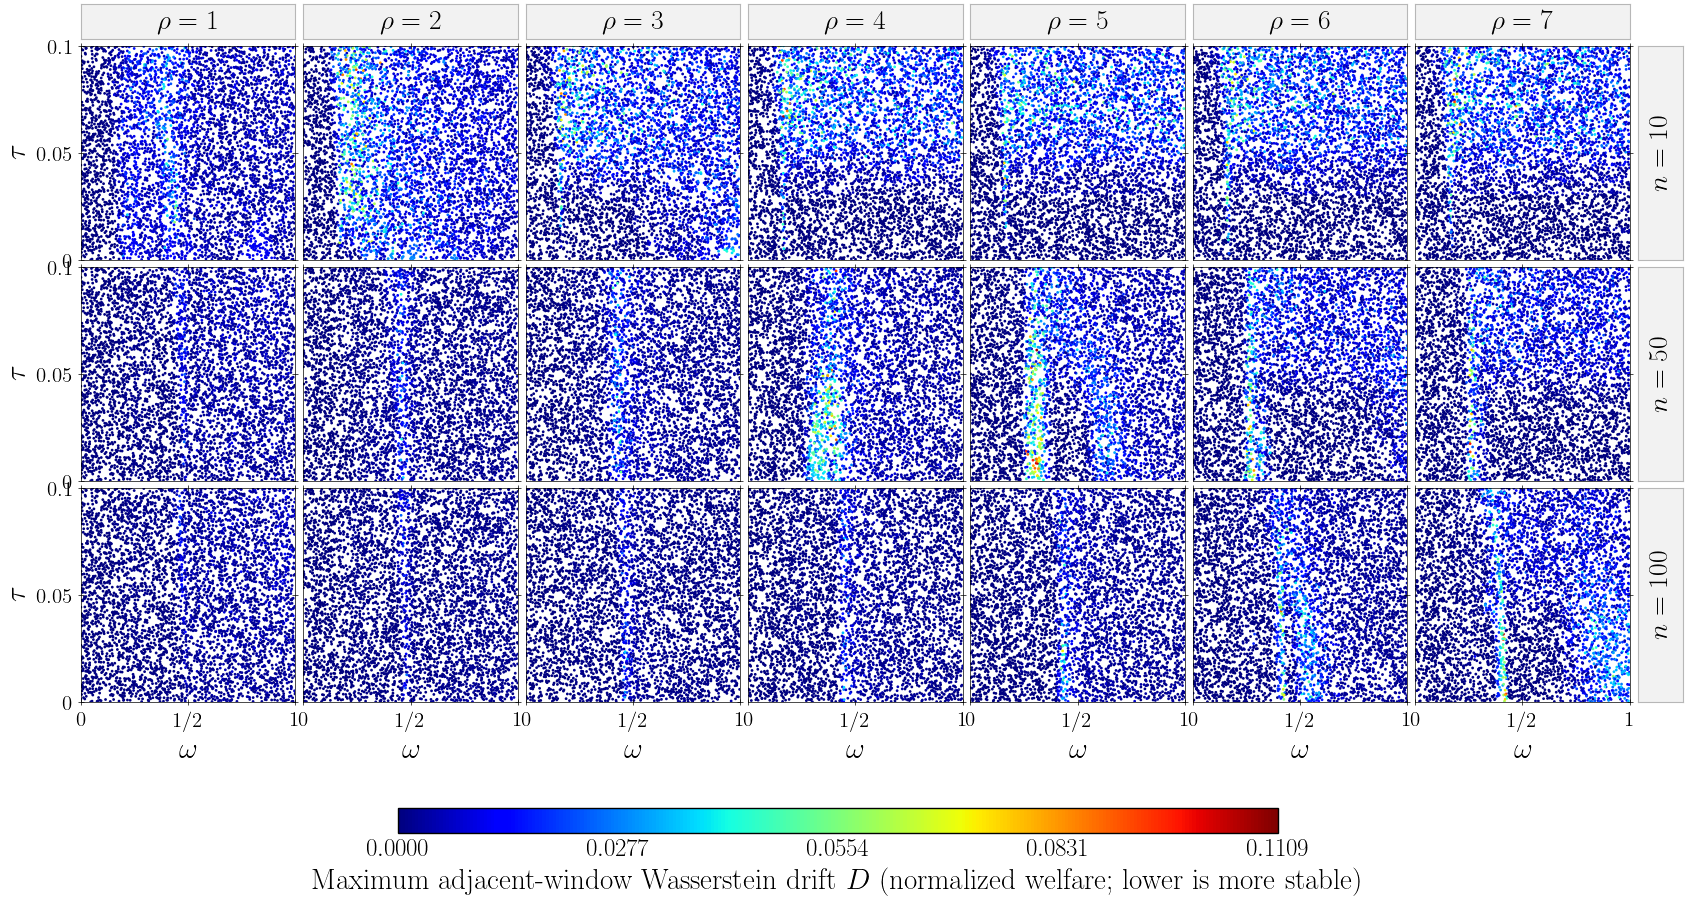

In [7]:
figure = plot_drift_grid(
    metrics["tail_distribution_drift"],
    results["theta"],
    composition_dim,
    composition,
)
display(figure)
plt.close(figure)

In [8]:
run_id = Path(CONFIG["result_store"]).stem
figure_dir = CONFIG["export"]["output_root"] / run_id
figure_dir.mkdir(parents=True, exist_ok=True)
pdf_path = figure_dir / (
    "centered_mean_welfare.mean__tail-drift__raw-points.pdf"
)
figure.savefig(
    pdf_path,
    format="pdf",
    dpi=CONFIG["export"]["dpi"],
    bbox_inches="tight",
)
print(f"Saved {pdf_path.relative_to(project_root)}")

Saved artifacts/figures/run-20260809T034029/centered_mean_welfare.mean__tail-drift__raw-points.pdf
